
# Virtual river gauges from satellites — student notebook
# Stations hydrométriques virtuelles par satellite — notebook étudiant

**Congo (DR Congo) · Rewa (Fiji) · and any river in the world** — **Congo (RD Congo) · Rewa (Fidji) · et toute rivière du monde**

**Start here · Commencez ici :** menu **Run ▸ Run all** (Colab: **Runtime ▸ Run all**), then read from the top.
Menu **Run ▸ Run all** (Colab : **Exécution ▸ Tout exécuter**), puis lisez depuis le début.

Every result comes from **real** satellite and model data (downloaded 3 November 2026 and shipped with the `virtualgauge` package, so it works offline). About 90 minutes.
Tous les résultats viennent de **vraies** données satellitaires et de modèle (téléchargées le 3 novembre 2026 et fournies avec le package `virtualgauge`, donc utilisables hors ligne). Environ 90 minutes.

✏️ a line you can change · une ligne à modifier — 🧪 try it · à vous — 💬 questions to discuss · questions à discuter

[![Open in Colab · Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simreaney/virtualgauge/blob/main/Virtual_River_Gauges_Student.ipynb)


In [1]:
#@title Setup · Configuration { display-mode: "form" }
import glob, importlib.util, subprocess, sys
if importlib.util.find_spec("virtualgauge") is None:          # install once (Colab / new computer)
    REPO_URL = "https://github.com/simreaney/virtualgauge"
    wheel = sorted(glob.glob("virtualgauge-*.whl"))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", wheel[-1] if wheel else f"git+{REPO_URL}"])
import virtualgauge as vg
print(f"virtualgauge {vg.__version__} — ready · prêt")

virtualgauge 0.1.0 — ready · prêt


Choose the language of figures and messages: `"en"`, `"fr"` or `"both"`.

> Choisissez la langue des figures et des messages : `"en"`, `"fr"` ou `"both"` (les deux).

In [2]:
vg.set_language("both")   # ✏️ "en", "fr" or/ou "both"

## Part 1 — Water levels on the Congo at Kinshasa · Partie 1 — Niveaux d'eau du Congo à Kinshasa

A **virtual station** is a place where satellites measure the same river again and again. Here we combine two:
**ICESat-2** (a laser, since 2018) and **SWOT** (a radar that maps whole rivers, since 2023). One line builds the station:

> Une **station virtuelle** est un endroit où les satellites mesurent la même rivière encore et encore. Nous en
> combinons deux : **ICESat-2** (un laser, depuis 2018) et **SWOT** (un radar qui cartographie des rivières entières,
> depuis 2023). Une ligne construit la station :

In [3]:
congo = vg.build_station("congo_kinshasa")
congo

Virtual station: Congo – Kinshasa · Station virtuelle : Congo – Kinshasa
ICESat-2: 21 water levels from 6 225 points (2019-02-10 → 2025-07-29). · ICESat-2 : 21 niveaux d'eau à partir de 6 225 points (2019-02-10 → 2025-07-29).
SWOT reach 13217000081: 62 of 108 observations kept (2023-08-31 → 2026-10-26). · Tronçon SWOT 13217000081 : 62 observations gardées sur 108 (2023-08-31 → 2026-10-26).
ICESat-2 − SWOT = -0.11 m (median of 5 near-simultaneous passes). · ICESat-2 − SWOT = -0.11 m (médiane de 5 passages quasi simultanés).
Data: saved copy in your cache folder, downloaded 2026-11-03. · Données : copie enregistrée dans votre dossier cache, téléchargée le 2026-11-03.
Next: .map(), .cleaning(), .slope(), .swot(), .levels(), .rating() · Ensuite : .map(), .cleaning(), .slope(), .swot(), .levels(), .rating()

### Where is it? · Où est-elle ?

The white outline is the **water mask** around the river centre-line; orange dots are ICESat-2 laser points. Switch to the satellite image with the layer button.

> Le contour blanc est le **masque d'eau** autour de la ligne centrale ; les points orange sont les points laser ICESat-2. Passez à l'image satellite avec le bouton des couches.

In [4]:
congo.map()

### Step 1 — Raw laser points · Étape 1 — Points laser bruts

Every point is a water height measured by ICESat-2, in metres above the **EGM2008 geoid** (≈ mean sea level), not above your gauge zero.

> Chaque point est une hauteur d'eau mesurée par ICESat-2, en mètres au-dessus du **géoïde EGM2008** (≈ niveau moyen des mers), pas au-dessus du zéro de votre échelle.

Step 1 — Raw ICESat-2 points · Étape 1 — Points ICESat-2 bruts
6 520 water-surface points from 27 satellite passes, 2018-11-11 → 2025-12-08. · 6 520 points de surface d'eau issus de 27 passages, 2018-11-11 → 2025-12-08.
Most points form a band — the river. Why might some sit metres above it? · La plupart des points forment une bande — la rivière. Pourquoi certains sont-ils des mètres au-dessus ?
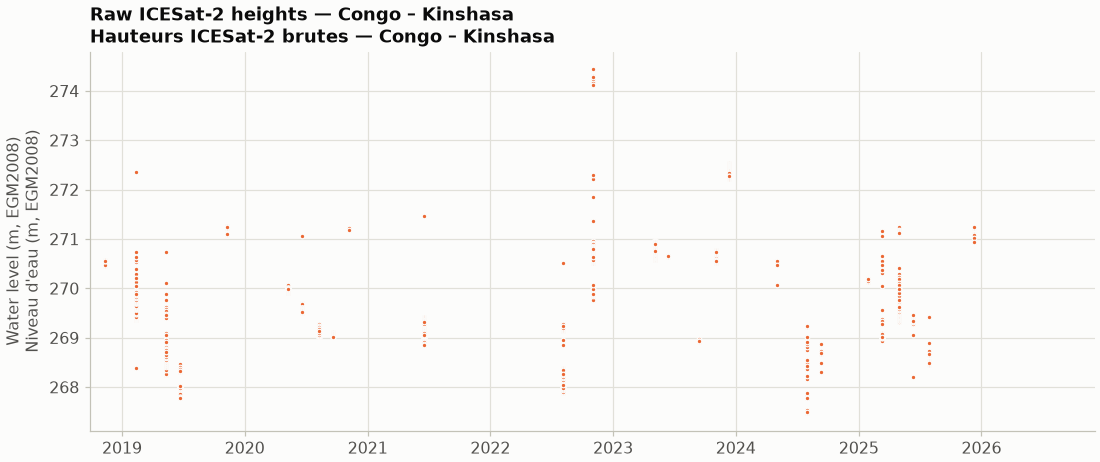

In [5]:
congo.raw_points()

💬 **What do you notice?**

- Most points form a band — the river. What could make the laser see a surface 10–40 m higher?

> 💬 **Qu'observez-vous ?**
>
> - La plupart des points forment une bande — le fleuve. Qu'est-ce qui pourrait faire voir au laser une surface 10 à 40 m plus haut ?

### Step 2 — Cleaning · Étape 2 — Nettoyage

Points are removed for four reasons: impossible level, not a river, cloudy, or an outlier within its pass. Every removal has a written reason.

> Les points sont retirés pour quatre raisons : niveau impossible, pas une rivière, nuageux, ou valeur aberrante dans son passage. Chaque retrait a une raison écrite.

,Reason · Raison,Count · Nombre
0,kept · gardé,6225
1,cloudy · nuageux,149
2,outlier in its pass · valeur aberrante dans son passage,133

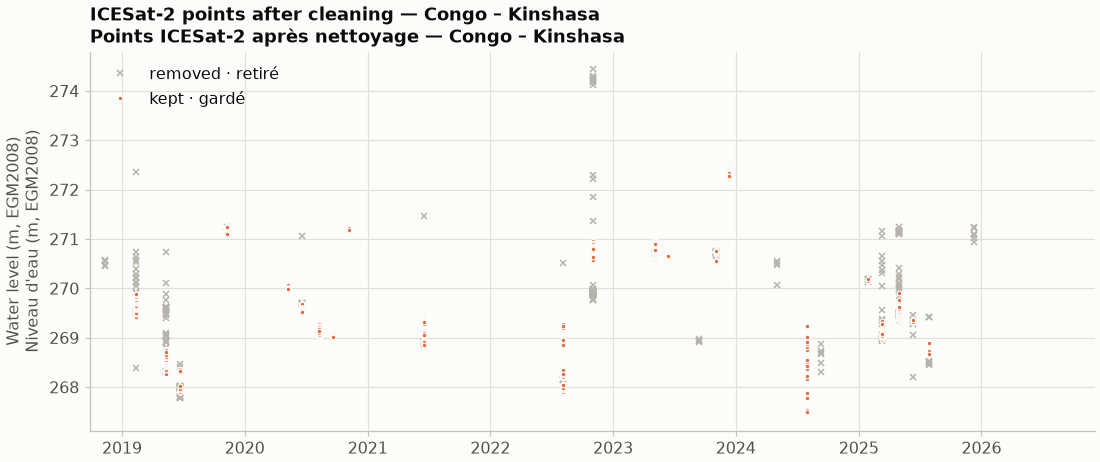

In [6]:
congo.cleaning()

💬 **What do you notice?**

- Which filter removes the most points?
- Look at the grey crosses: were any real water levels removed?

> 💬 **Qu'observez-vous ?**
>
> - Quel filtre retire le plus de points ?
> - Regardez les croix grises : de vrais niveaux d'eau ont-ils été retirés ?

### Step 3 — The river surface slopes · Étape 3 — La surface du fleuve est en pente

Each laser pass crosses the reach at a different place. The water surface falls downstream, so the points are corrected to the middle of the reach before taking one level per pass.

> Chaque passage laser croise le tronçon à un endroit différent. La surface de l'eau descend vers l'aval : les points sont ramenés au milieu du tronçon avant de prendre un niveau par passage.

,pass_id,slope_m_per_km,n_points,span_km
0,2019-02-10_rgt669,0.106,1109,4.36
1,2019-05-12_rgt669,0.116,279,4.26
2,2019-11-09_rgt669,0.017,49,2.69
3,2021-06-18_rgt1301,0.129,259,4.54
4,2022-08-04_rgt669,0.082,94,4.26
5,2022-11-03_rgt669,0.051,1072,4.26
6,2023-05-04_rgt669,0.057,999,4.26
7,2023-12-13_rgt1301,0.081,630,2.17
8,2024-07-31_rgt669,0.343,49,4.26
9,2025-04-29_rgt669,0.008,360,7.36

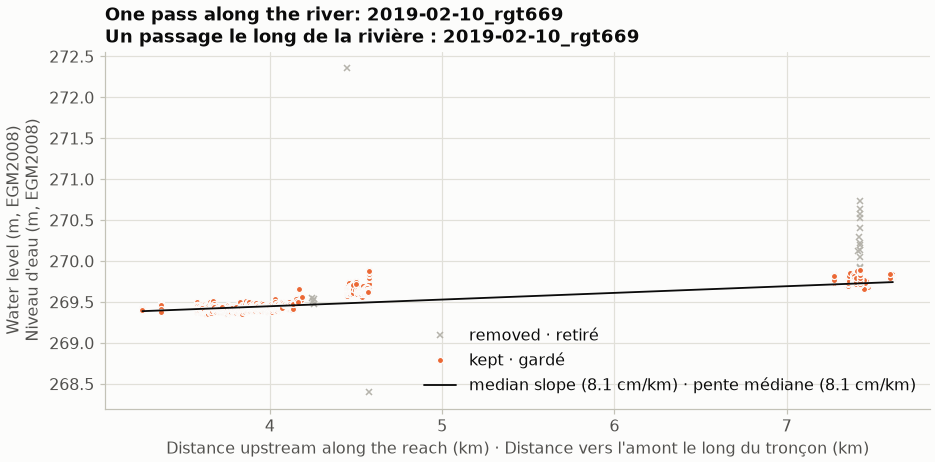

In [7]:
congo.slope()

💬 **What do you notice?**

- Is a slope of about 8 cm per km plausible for a very large river?
- Why might one pass give a much larger slope than the others? (look at its number of points)

> 💬 **Qu'observez-vous ?**
>
> - Une pente d'environ 8 cm par km est-elle plausible pour un très grand fleuve ?
> - Pourquoi un passage donne-t-il une pente bien plus forte que les autres ? (regardez son nombre de points)

,pass_id,time,wse_m,wse_u_m,n_points
0,2019-02-10_rgt669,2019-02-10 08:52:58.881074176,270,0.1,1109
1,2019-05-12_rgt669,2019-05-12 04:32:38.532051200,268,0.1,279
2,2019-06-22_rgt1301,2019-06-22 14:32:55.298259456,268,0.102,24
3,2019-11-09_rgt669,2019-11-09 19:52:14.638722048,271,0.1,49
4,2020-05-09_rgt669,2020-05-09 11:11:48.098031616,270,0.1,973
5,2020-06-19_rgt1301,2020-06-19 21:12:08.011817984,270,0.1,156
6,2020-08-08_rgt669,2020-08-08 06:51:32.872327424,269,0.101,52
7,2020-09-18_rgt1301,2020-09-18 16:51:55.656702208,269,0.1,24
8,2021-06-18_rgt1301,2021-06-18 03:51:29.376819968,269,0.1,259
9,2022-08-04_rgt669,2022-08-04 20:10:42.372601856,268,0.101,94

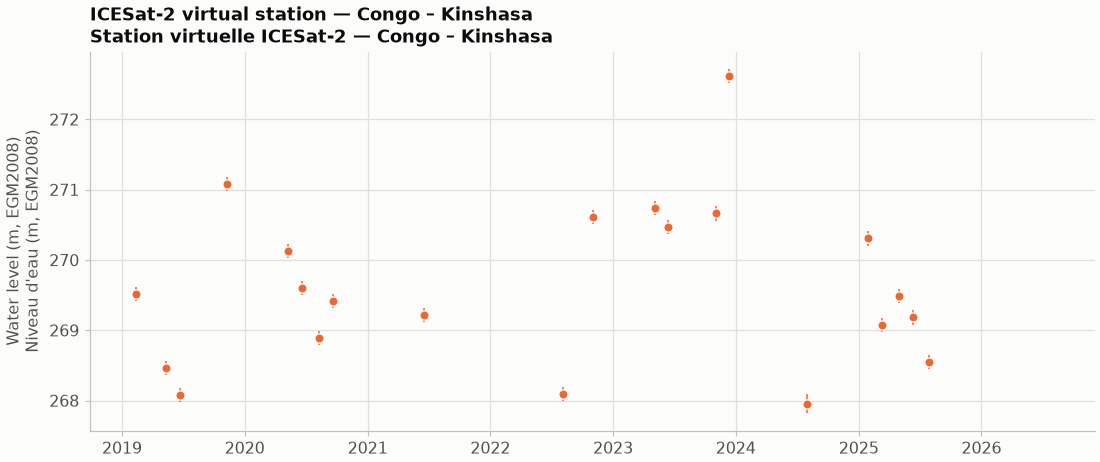

In [8]:
congo.icesat_levels()

### Step 4 — SWOT · Étape 4 — SWOT

SWOT gives one level for the whole ~10 km reach at each pass. We keep good quality flags and check that **water flows downhill**: our reach cannot be higher than the reach upstream at the same moment.

> SWOT donne un niveau pour tout le tronçon de ~10 km à chaque passage. On garde les bons indicateurs de qualité et on vérifie que **l'eau descend** : notre tronçon ne peut pas être plus haut que l'amont au même moment.

,Reason · Raison,Count · Nombre
0,kept · gardé,62
1,quality flag reach_q > 1 · indicateur reach_q > 1,46

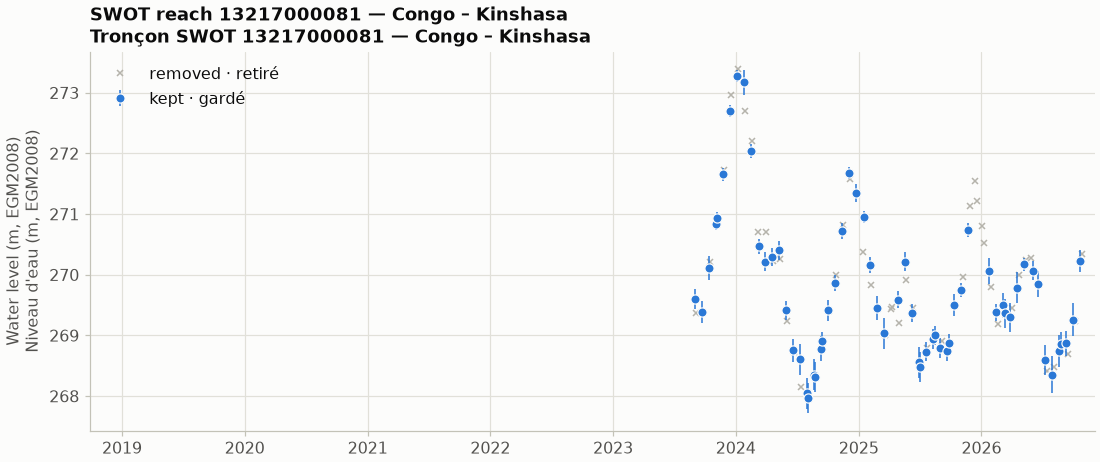

In [9]:
congo.swot()

💬 **What do you notice?**

- How many SWOT levels per year do we get, compared with ICESat-2?
- Why do you think so many observations fail the quality flags?

> 💬 **Qu'observez-vous ?**
>
> - Combien de niveaux SWOT par an obtient-on, comparé à ICESat-2 ?
> - Pourquoi, à votre avis, tant d'observations échouent-elles aux indicateurs de qualité ?

### Step 5 — Two satellites, one station · Étape 5 — Deux satellites, une station

When both satellites passed within 3 days, we compare them and shift ICESat-2 onto SWOT.

> Quand les deux satellites sont passés à moins de 3 jours d'intervalle, on les compare et on ramène ICESat-2 sur SWOT.

In [10]:
congo.agreement()

,time,wse_m,time_swot,wse_swot,days_apart,difference_m
13,2023-11-01 22:28:43.847729920,271,2023-11-02 00:54:25,271,-0.1,-0.184
14,2023-12-13 08:29:03.856563712,273,2023-12-13 18:24:34,273,-0.4,-0.083
15,2024-07-31 09:27:17.752075264,268,2024-07-30 06:40:27,268,1.1,-0.098
18,2025-04-29 20:26:08.591902720,269,2025-04-27 12:26:29,270,2.3,-0.109
19,2025-06-10 06:26:20.786686208,269,2025-06-08 05:56:39,269,2,-0.184


,SWOT,ICESat-2,all
observations,62,21,83
first,2023-08-31,2019-02-10,2019-02-10
last,2026-10-21,2025-07-29,2026-10-21
per_year,19.7,3.2,10.8
median_gap_days,20.9,70.1,20.9
longest_gap_days,62.6,413,413

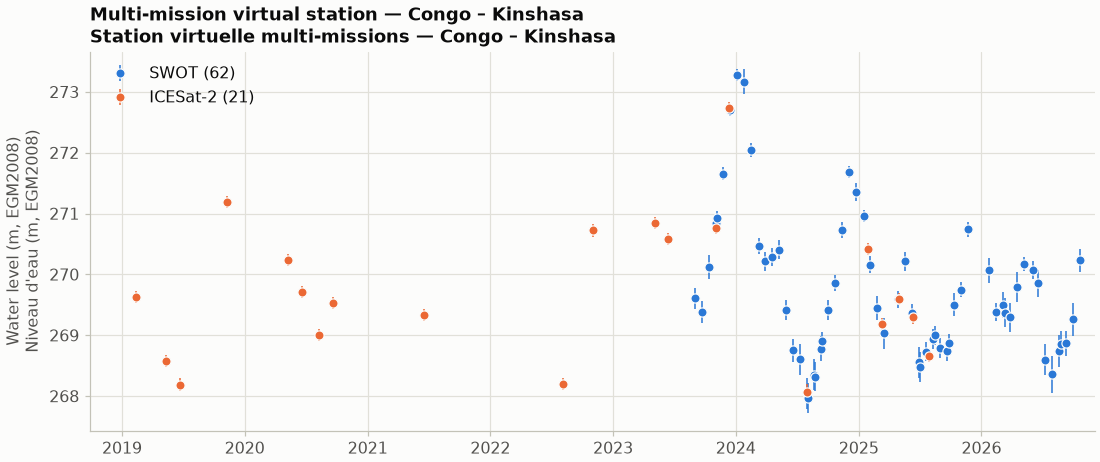

In [11]:
congo.levels()

💬 **What do you notice?**

- When are the lowest and highest levels of the year?
- Something unusual happened at the end of 2023 — what do you see?
- Is an offset from only 5 pairs reliable?

> 💬 **Qu'observez-vous ?**
>
> - Quand surviennent les niveaux les plus bas et les plus hauts de l'année ?
> - Quelque chose d'inhabituel s'est produit fin 2023 — que voyez-vous ?
> - Un décalage estimé sur seulement 5 paires est-il fiable ?

## Part 2 — From level to discharge · Partie 2 — Du niveau au débit

A **rating curve** turns water level into discharge: **Q = a · (h − h₀)ᵇ**. To fit it we need discharge on the days
the satellites looked. With no open gauge data for these years, we use the **GEOGloWS model** — and we must check it.

> Une **courbe de tarage** transforme le niveau en débit : **Q = a · (h − h₀)ᵇ**. Pour l'ajuster, il faut des débits aux
> dates des passages. Sans données de station ouvertes pour ces années, on utilise le **modèle GEOGloWS** — et il faut le vérifier.

Step 7 — Reference discharge · Étape 7 — Débit de référence
Reference discharge: GEOGloWS model, 1940-01-01 → 2026-10-16. · Débit de référence : modèle GEOGloWS, 1940-01-01 → 2026-10-16.
Automatic GEOGloWS river lookup at this point: river 130594908, mean flow 1.1 m³/s. · Recherche automatique GEOGloWS à ce point : rivière 130594908, débit moyen 1.1 m³/s.
River chosen by hand: 130798640, mean flow 62 795 m³/s. Always check the river ID on a map. · Rivière choisie à la main : 130798640, débit moyen 62 795 m³/s. Vérifiez toujours l'identifiant sur une carte.
! This is a model, not a measurement. Your own gauge data would be better. · C'est un modèle, pas une mesure. Vos propres données de station seraient meilleures.
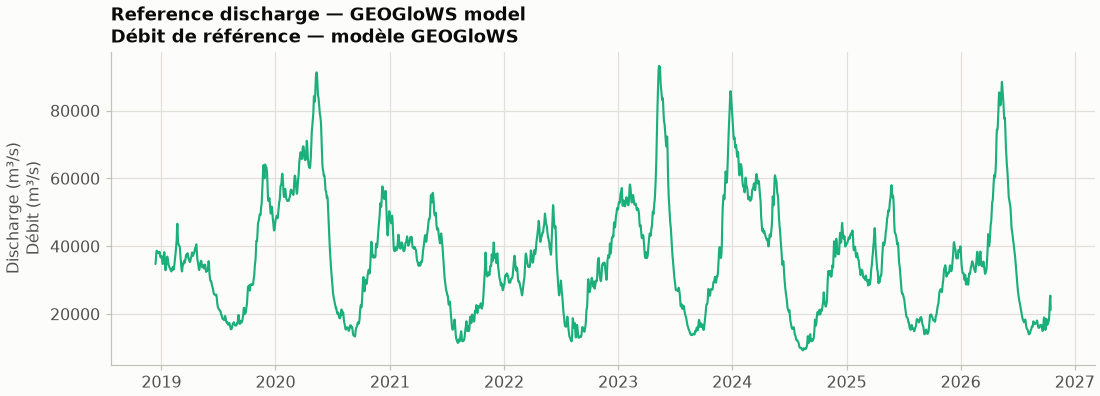

In [12]:
congo.reference_discharge()

💬 **What do you notice?**

- The automatic river lookup found a river with about 1 m³/s. Why is that a problem?

> 💬 **Qu'observez-vous ?**
>
> - La recherche automatique a trouvé une rivière d'environ 1 m³/s. Pourquoi est-ce un problème ?

,n,r,NSE,KGE,RMSE,PBIAS %
fit,82,0.699,0.473,0.618,"12,944",-5.32

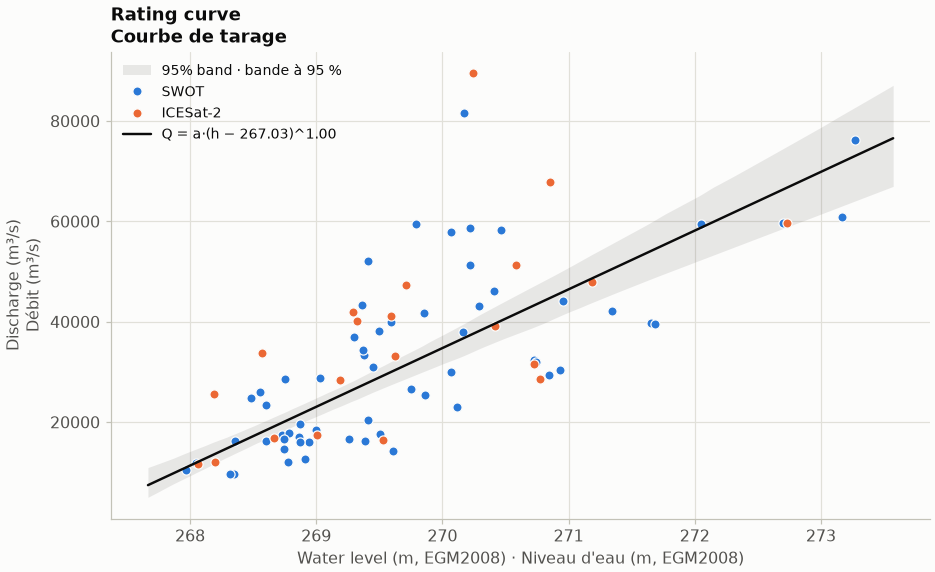

In [13]:
congo.rating()

💬 **What do you notice?**

- What does the warning “b is at its limit” tell you?
- Is NSE = 0.47 good enough for a flow gauge?

> 💬 **Qu'observez-vous ?**
>
> - Que vous dit l'avertissement « b est à sa limite » ?
> - Un NSE de 0,47 suffit-il pour une station de débit ?

month,1,2,3,4,5,6,7,8,9,10,11,12
median,-4,9,32,35,87,50,-2,-20,-34,-36,-27,-13
count,5,5,7,4,7,10,8,11,8,4,9,4

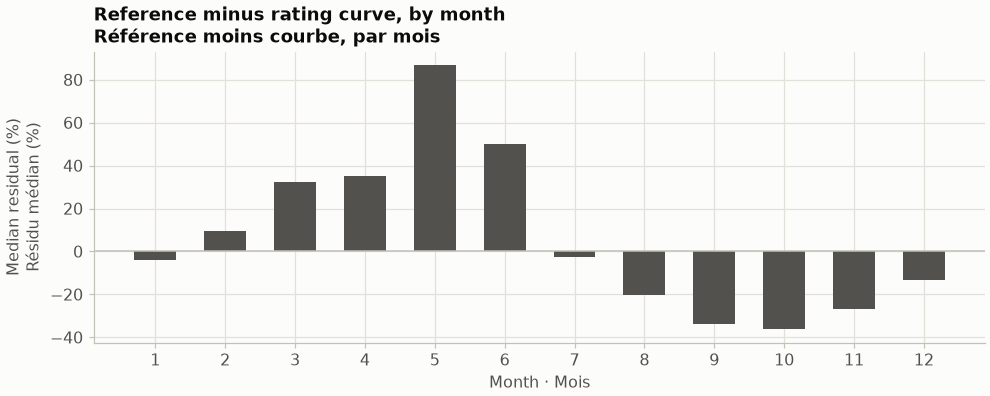

In [14]:
congo.residuals_by_month()

💬 **What do you notice?**

- Kinshasa's level is controlled by rock rapids just downstream, which do not move. So is this seasonal pattern caused by the river, or by the model?

> 💬 **Qu'observez-vous ?**
>
> - Le niveau à Kinshasa est contrôlé par des rapides rocheux juste en aval, qui ne bougent pas. Cette structure saisonnière vient-elle du fleuve ou du modèle ?

Leave out the months where the model disagrees with the satellites, and fit again:

> Excluez les mois où le modèle contredit les satellites, et ajustez à nouveau :

,n,r,NSE,KGE,RMSE,PBIAS %
all months,82,0.699,0.473,0.618,"12,944",-5.32
fit months only,54,0.94,0.882,0.911,5.24e+03,-1.89

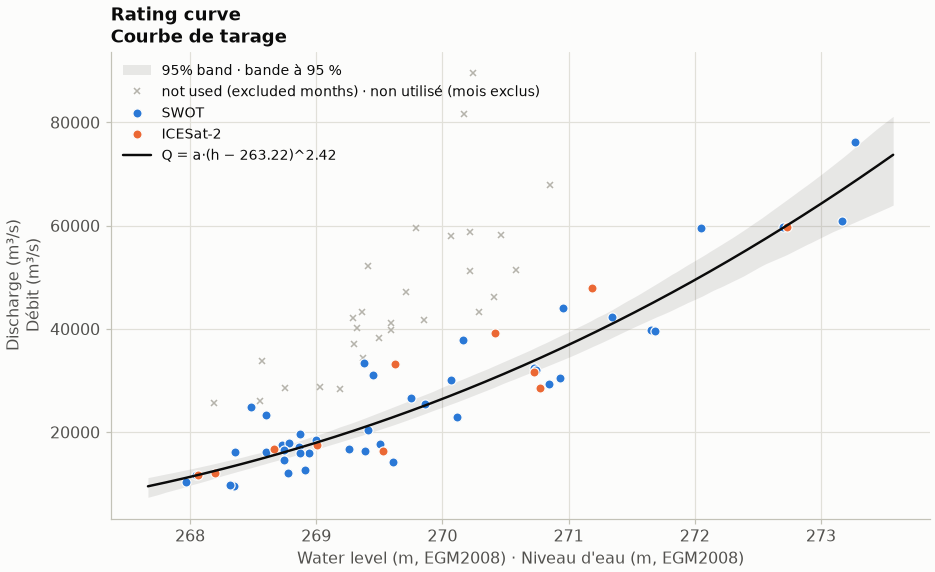

In [15]:
congo.rating(exclude_months=[3, 4, 5, 6])   # ✏️ try other months · essayez d'autres mois

In [16]:
congo.split_test("2025-01-01")

,n,r,NSE,KGE,RMSE,PBIAS %
train,31,0.968,0.936,0.944,4.64e+03,-1.39
test,23,0.844,0.329,0.597,7.1e+03,-22.1


💬 **What do you notice?**

- The curve fits the earlier years well. Why is it worse on 2025–2026?
- What do we lose by leaving months out?

> 💬 **Qu'observez-vous ?**
>
> - La courbe s'ajuste bien aux premières années. Pourquoi est-elle moins bonne en 2025–2026 ?
> - Que perd-on en excluant des mois ?

,count,mean,std,min,25%,50%,75%,max
wse_m,83,270,1.2,268,269,270,270,273
Q_m3s,83,"25,498","12,129","11,155","16,982","22,015","29,895","68,667"

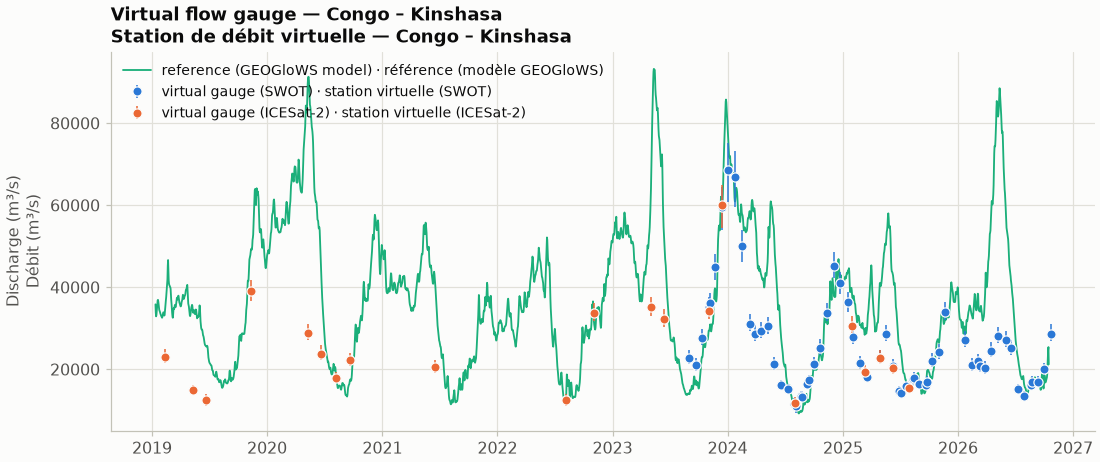

In [17]:
congo.discharge()

💬 **What do you notice?**

- The long-term mean flow measured at Kinshasa since 1903 is about 40,000 m³/s. How does our virtual gauge compare, and why?

> 💬 **Qu'observez-vous ?**
>
> - Le débit moyen mesuré à Kinshasa depuis 1903 est d'environ 40 000 m³/s. Comment notre station virtuelle se compare-t-elle, et pourquoi ?

Save the result as a CSV file for your agency (folder `outputs/`). On Colab use `congo.export(download=True)`.

> Enregistrez le résultat en CSV pour votre service (dossier `outputs/`). Sur Colab, utilisez `congo.export(download=True)`.

In [18]:
congo.export()

Export
Written: outputs/congo_kinshasa_virtual_gauge.csv · Écrit : outputs/congo_kinshasa_virtual_gauge.csv
Written: outputs/congo_kinshasa_virtual_gauge_metadata.json · Écrit : outputs/congo_kinshasa_virtual_gauge_metadata.json

## Part 3 — The Rewa, Fiji · Partie 3 — La Rewa, Fidji

The same method on a river 100–400 m wide, with cyclone floods that last hours to days, and a tidal lower course.

> La même méthode sur une rivière de 100 à 400 m de large, avec des crues cycloniques de quelques heures à quelques jours, et un cours inférieur soumis à la marée.

In [19]:
rewa = vg.build_station("rewa_fiji")
rewa

Virtual station: Rewa – Fiji · Station virtuelle : Rewa – Fiji
ICESat-2: 18 water levels from 875 points (2018-12-26 → 2025-06-17). · ICESat-2 : 18 niveaux d'eau à partir de 875 points (2018-12-26 → 2025-06-17).
SWOT reach 55200000051: 82 of 108 observations kept (2023-07-28 → 2026-10-29). · Tronçon SWOT 55200000051 : 82 observations gardées sur 108 (2023-07-28 → 2026-10-29).
ICESat-2 − SWOT = +0.07 m (median of 3 near-simultaneous passes). · ICESat-2 − SWOT = +0.07 m (médiane de 3 passages quasi simultanés).
Data: saved copy in your cache folder, downloaded 2026-11-03. · Données : copie enregistrée dans votre dossier cache, téléchargée le 2026-11-03.
Next: .map(), .cleaning(), .slope(), .swot(), .levels(), .rating() · Ensuite : .map(), .cleaning(), .slope(), .swot(), .levels(), .rating()

,SWOT,ICESat-2,all
observations,82,18,100
first,2023-07-28,2018-12-26,2018-12-26
last,2026-10-22,2025-06-17,2026-10-22
per_year,25.4,2.8,12.8
median_gap_days,13.4,90.8,13.4
longest_gap_days,55.1,454,454

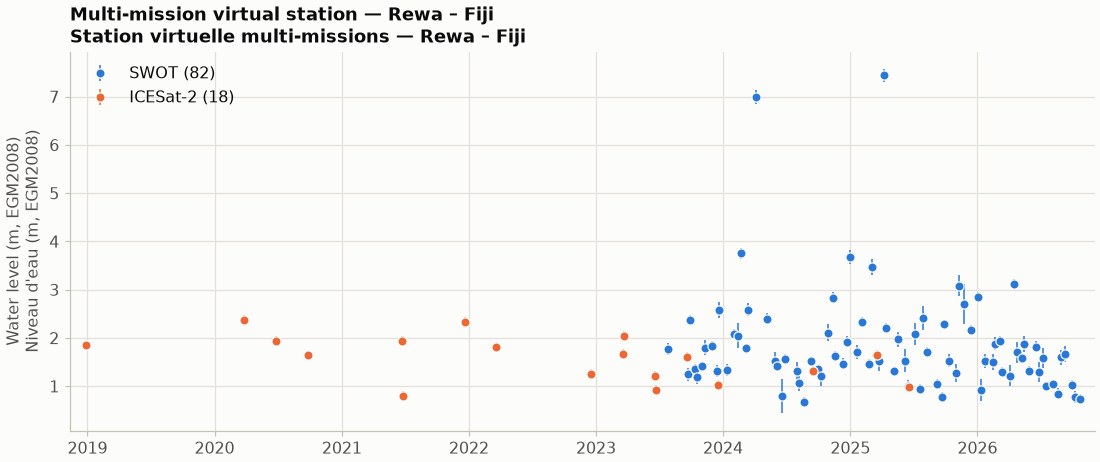

In [20]:
rewa.levels()

,pass_id,slope_m_per_km,n_points,span_km
0,2018-12-26_rgt1357,0.031,45,6.03
1,2020-09-25_rgt21,0.041,223,12.2
2,2023-03-22_rgt21,0.052,102,4.02

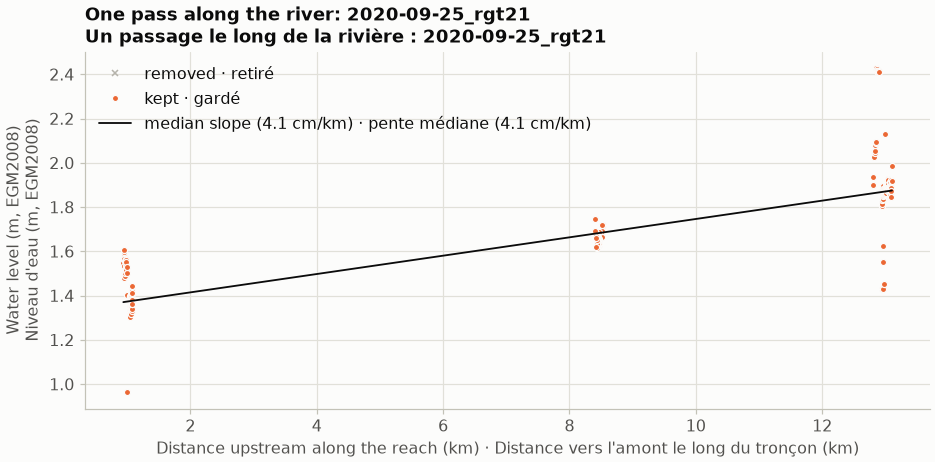

In [21]:
rewa.slope()

💬 **What do you notice?**

- One pass has a negative slope: the water surface rises towards the sea. How can the tide explain that?

> 💬 **Qu'observez-vous ?**
>
> - Un passage a une pente négative : la surface de l'eau monte vers la mer. Comment la marée peut-elle l'expliquer ?

,Reason · Raison,Count · Nombre
0,kept · gardé,82
1,quality flag reach_q > 1 · indicateur reach_q > 1,20
2,higher than the reach upstream · plus haut que le tronçon amont,6

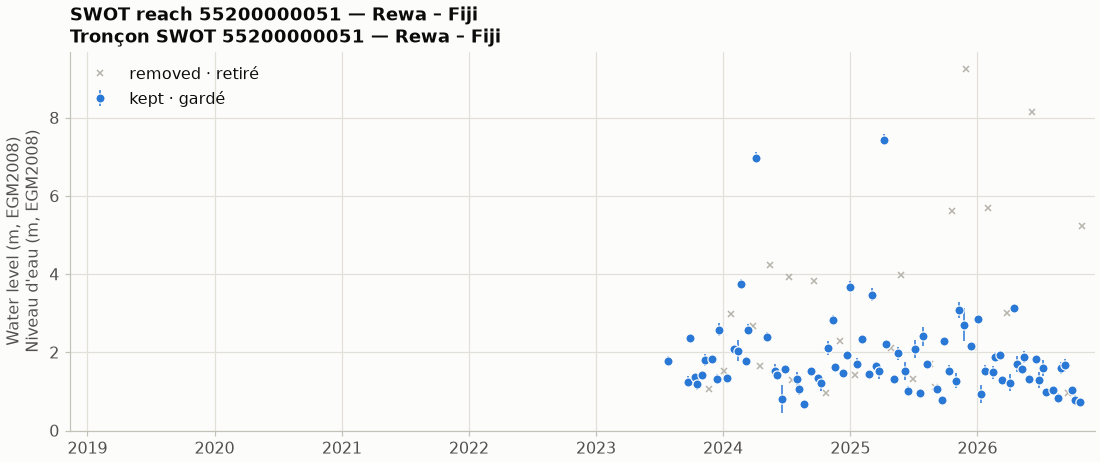

In [22]:
rewa.swot()

💬 **What do you notice?**

- Some very high SWOT values were removed because they were higher than the reach upstream. Real floods, or errors?

> 💬 **Qu'observez-vous ?**
>
> - Des valeurs SWOT très hautes ont été retirées car plus hautes que le tronçon amont. Vraies crues ou erreurs ?

Three reaches of the same river · Trois tronçons de la même rivière
Nausori (tidal · marée): 40 levels, 0.16–1.74 m. · Nausori (tidal · marée) : 40 niveaux, 0.16–1.74 m.
Main · Principal (051): 82 levels, 0.68–7.44 m. · Main · Principal (051) : 82 niveaux, 0.68–7.44 m.
Upstream · Amont (061): 92 levels, 1.72–8.02 m. · Upstream · Amont (061) : 92 niveaux, 1.72–8.02 m.
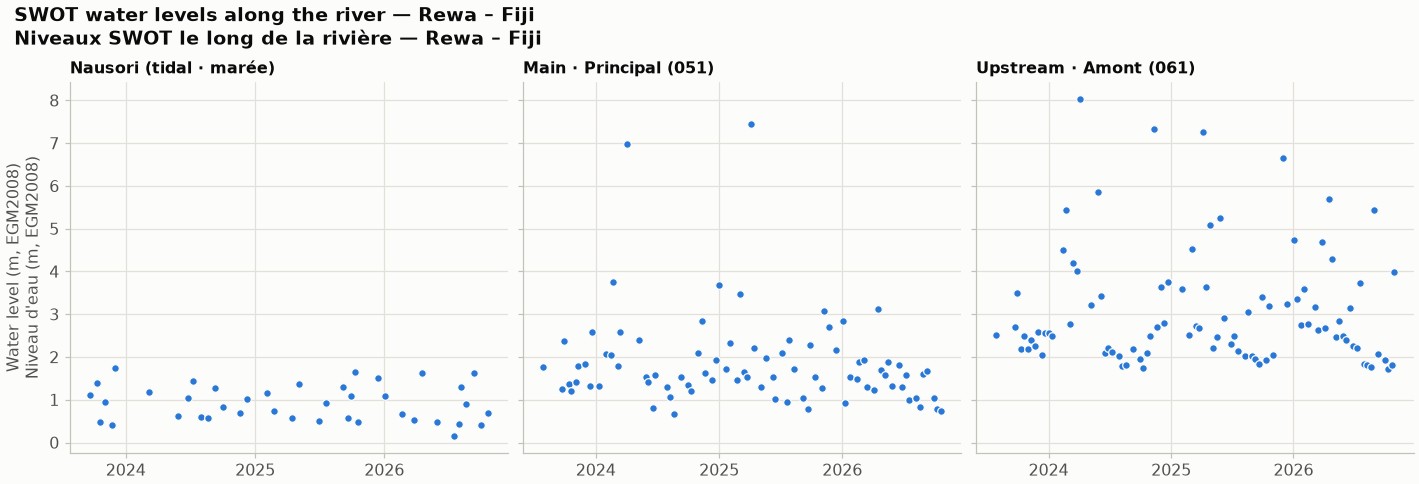

In [23]:
rewa.compare_reaches()

💬 **What do you notice?**

- Nausori stays between about 0.2 and 1.7 m all year. Why?
- Where would you put a virtual station to estimate discharge?

> 💬 **Qu'observez-vous ?**
>
> - Nausori reste entre environ 0,2 et 1,7 m toute l'année. Pourquoi ?
> - Où placeriez-vous une station virtuelle pour estimer le débit ?

,1 d · j,2 d · j,3 d · j,5 d · j,10 d · j,30 d · j
Congo – Kinshasa: SWOT,5,11,16,26,48,96
Congo – Kinshasa: SWOT + ICESat-2,6,12,17,28,50,96
Rewa – Fiji: SWOT,7,14,20,34,62,97
Rewa – Fiji: SWOT + ICESat-2,7,14,21,35,63,97

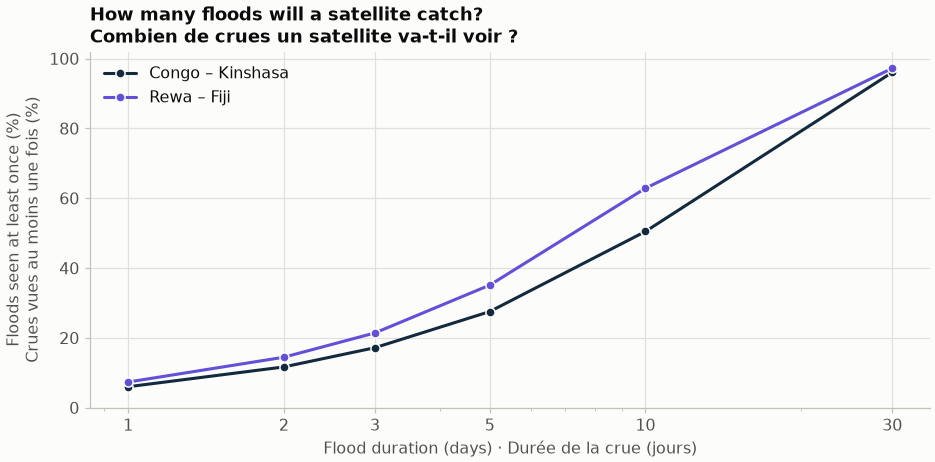

In [24]:
vg.flood_catch(congo, rewa)

💬 **What do you notice?**

- What chance does a satellite have of seeing a 1-day cyclone flood? And a 30-day Congo flood?
- What does this mean for flood warning?

> 💬 **Qu'observez-vous ?**
>
> - Quelle chance un satellite a-t-il de voir une crue cyclonique d'un jour ? Et une crue du Congo de 30 jours ?
> - Qu'est-ce que cela signifie pour l'alerte aux crues ?

In [25]:
rewa.rating()

Step 7 — Rating curve · Étape 7 — Courbe de tarage
No reference discharge for this site: there is no open discharge record and no model river is set. Add your own gauge data as data/gauge_rewa_fiji.csv (columns date, stage_m, discharge_m3s) to fit a rating curve. · Pas de débit de référence pour ce site : aucune série ouverte et aucune rivière de modèle. Ajoutez vos données dans data/gauge_rewa_fiji.csv (colonnes date, stage_m, discharge_m3s) pour ajuster une courbe.

🧪 Try it: switch the slope correction off for the Rewa and compare the levels with the ones above.

> 🧪 À vous : désactivez la correction de pente pour la Rewa et comparez avec les niveaux ci-dessus.

,SWOT,ICESat-2,all
observations,82,18,100
first,2023-07-28,2018-12-26,2018-12-26
last,2026-10-22,2025-06-17,2026-10-22
per_year,25.4,2.8,12.8
median_gap_days,13.4,90.8,13.4
longest_gap_days,55.1,454,454

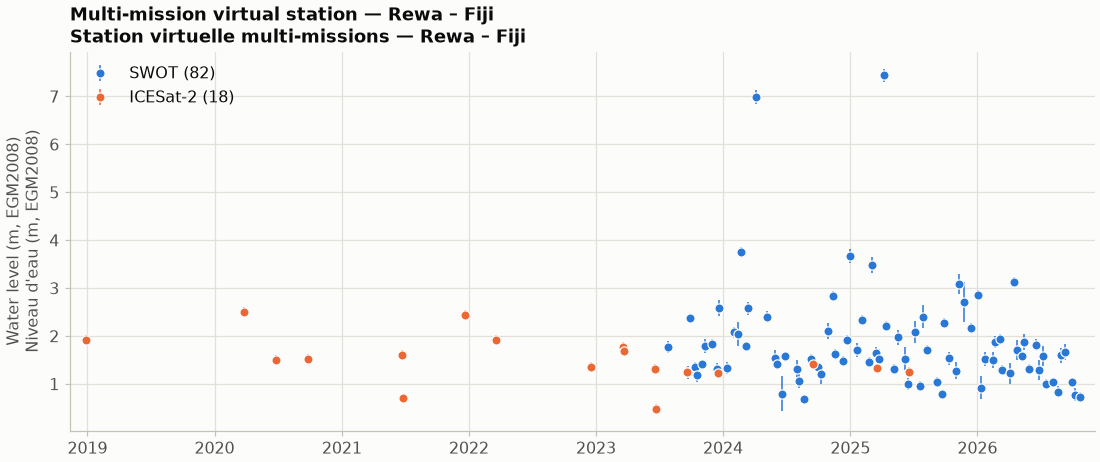

In [26]:
vg.build_station("rewa_fiji", slope_correction=False).levels()   # ✏️

## Part 4 — Explore the settings · Partie 4 — Explorer les réglages

Move the sliders and click the months. Three tasks:
1. Choose the Rewa and set **ICESat-2 max cloud** to 0. How many levels are left?
2. Set the **up/downstream tolerance** to 2 m. Do the impossible "floods" come back?
3. For Kinshasa, add March–June back one month at a time. What happens to *b* and the curve?

> Déplacez les curseurs et cliquez sur les mois. Trois tâches :
> 1. Choisissez la Rewa et mettez **ICESat-2 nuages max** à 0. Combien de niveaux restent-ils ?
> 2. Mettez la **tolérance amont/aval** à 2 m. Les « crues » impossibles reviennent-elles ?
> 3. Pour Kinshasa, remettez mars à juin un mois à la fois. Que deviennent *b* et la courbe ?

In [27]:
vg.explore()

## Part 5 — Explore more locations · Partie 5 — Explorer d'autres lieux

Every dot is a SWOT river reach on the Congo and its large tributaries — a possible virtual station. Darker dots are seen more often by SWOT. Click a dot to get its ID and the line of code to build it. Orange markers are stations shipped with the package.

> Chaque point est un tronçon SWOT du Congo et de ses grands affluents — une station virtuelle possible. Les points foncés sont vus plus souvent par SWOT. Cliquez sur un point pour son identifiant et la ligne de code. Les marqueurs orange sont des stations fournies avec le package.

In [28]:
vg.congo_map()

In [29]:
vg.sites()

,name,river,lat,lon,swot_reach,discharge_model
key,,,,,,
congo_kinshasa,Congo – Kinshasa,Congo,-4.270000,15.336000,13217000081,True
rewa_fiji,Rewa – Fiji,Rewa,-17.961000,178.435000,55200000051,False
congo_kisangani,Congo – Kisangani,Congo,0.487361,25.210104,13279300031,True
congo_mbandaka,Congo – Mbandaka,Congo,0.138262,18.238421,13273000011,True
ubangi_bangui,Ubangi – Bangui,Ubangi,4.154015,18.622650,13263100051,True
kasai_kwamouth,Kasai – Kwamouth,Kasai,-3.089236,16.363962,13221000021,True
lualaba_kindu,Lualaba – Kindu,Lualaba,-3.114339,25.940776,13279900051,True
sangha_ouesso,Sangha – Ouesso,Sangha,1.450279,16.176239,13245000311,True


### Down the river · Le long du fleuve

Water levels at seven stations, from the upper Congo (Lualaba at Kindu) to Kinshasa. Each panel shows the level minus its median.

> Les niveaux de sept stations, du haut Congo (Lualaba à Kindu) jusqu'à Kinshasa. Chaque panneau montre le niveau moins sa médiane.

Comparing stations along the river · Comparaison de stations le long de la rivière
Lualaba – Kindu: highest levels on average in month 5. · Lualaba – Kindu : niveaux les plus hauts en moyenne au mois 5.
Congo – Kisangani: highest levels on average in month 4. · Congo – Kisangani : niveaux les plus hauts en moyenne au mois 4.
Congo – Mbandaka: highest levels on average in month 1. · Congo – Mbandaka : niveaux les plus hauts en moyenne au mois 1.
Ubangi – Bangui: highest levels on average in month 11. · Ubangi – Bangui : niveaux les plus hauts en moyenne au mois 11.
Sangha – Ouesso: highest levels on average in month 10. · Sangha – Ouesso : niveaux les plus hauts en moyenne au mois 10.
Kasai – Kwamouth: highest levels on average in month 12. · Kasai – Kwamouth : niveaux les plus hauts en moyenne au mois 12.
Congo – Kinshasa: highest levels on average in month 12. · Congo – Kinshasa : niveaux les plus hauts en moyenne au mois 12.
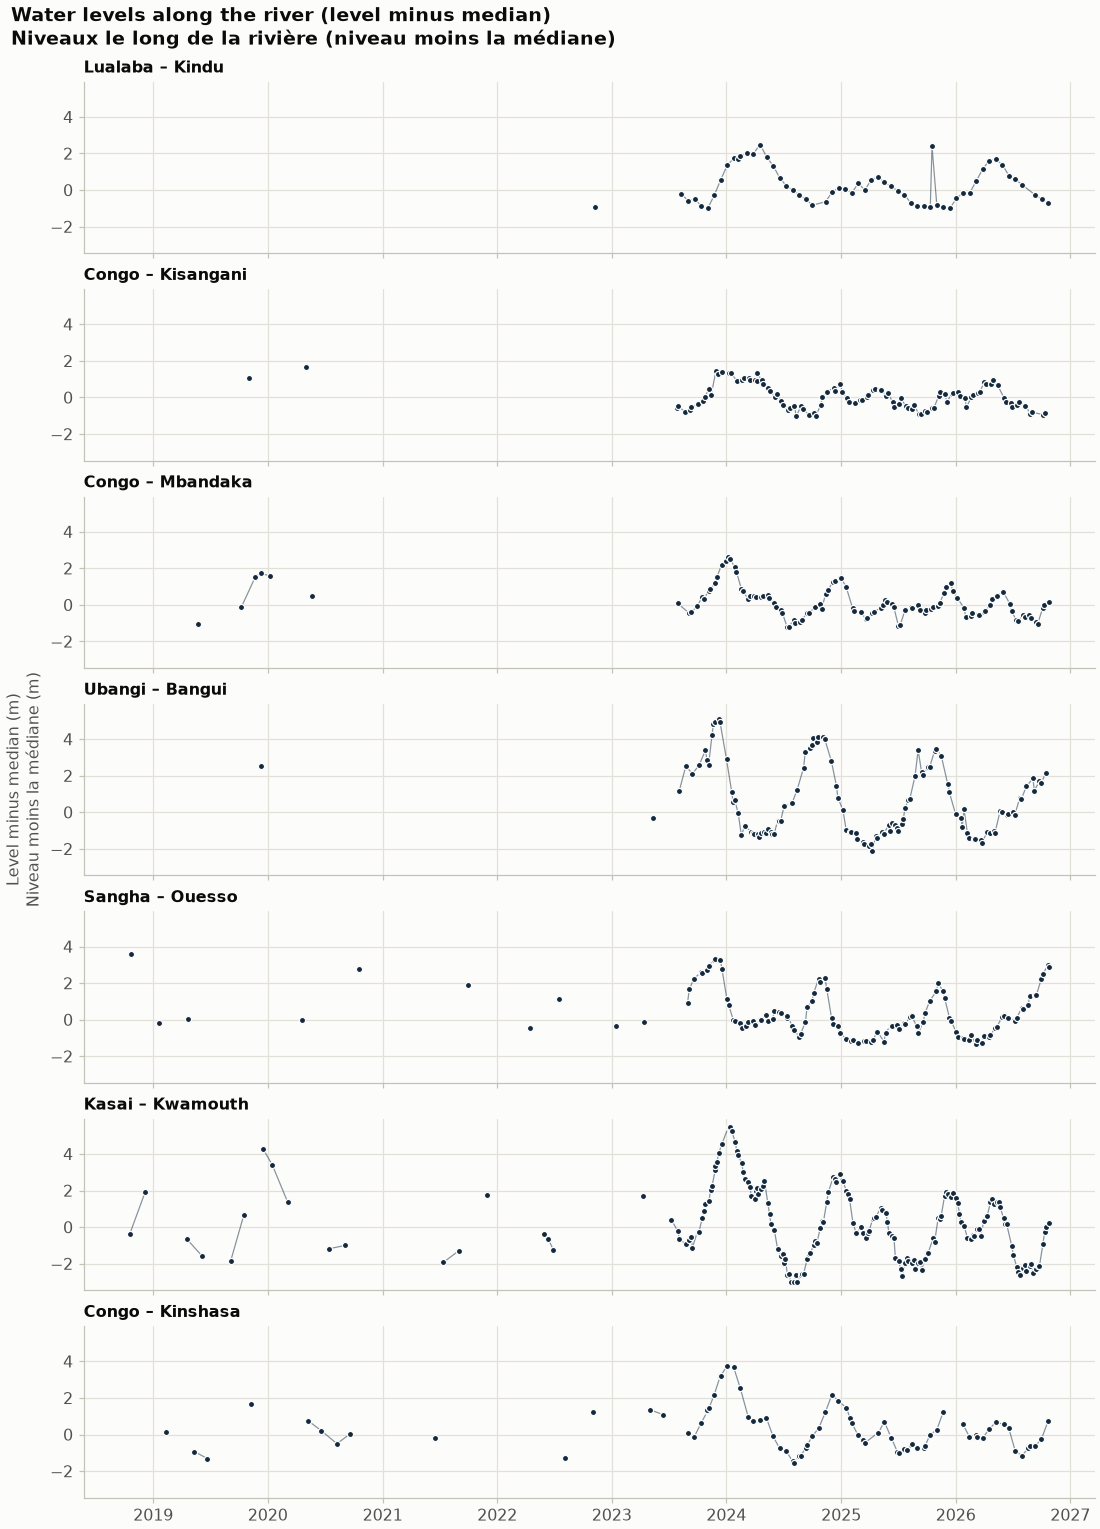

In [30]:
vg.compare_stations(["lualaba_kindu", "congo_kisangani", "congo_mbandaka", "ubangi_bangui",
                     "sangha_ouesso", "kasai_kwamouth", "congo_kinshasa"])

💬 **What do you notice?**

- Which rivers peak in October–December, and which in April–May?
- Kinshasa has two high-water seasons each year. Which tributaries explain each one?
- Which river has the biggest seasonal range?

> 💬 **Qu'observez-vous ?**
>
> - Quelles rivières culminent en octobre–décembre, et lesquelles en avril–mai ?
> - Kinshasa a deux saisons de hautes eaux par an. Quels affluents expliquent chacune ?
> - Quelle rivière a la plus grande amplitude saisonnière ?

🧪 Try it: build any station from the list above and fit its rating curve, e.g. the Ubangi at Bangui.

> 🧪 À vous : construisez n'importe quelle station de la liste et ajustez sa courbe de tarage, par ex. l'Oubangui à Bangui.

,n,r,NSE,KGE,RMSE,PBIAS %
fit,117,0.928,0.857,0.871,735,-4.85

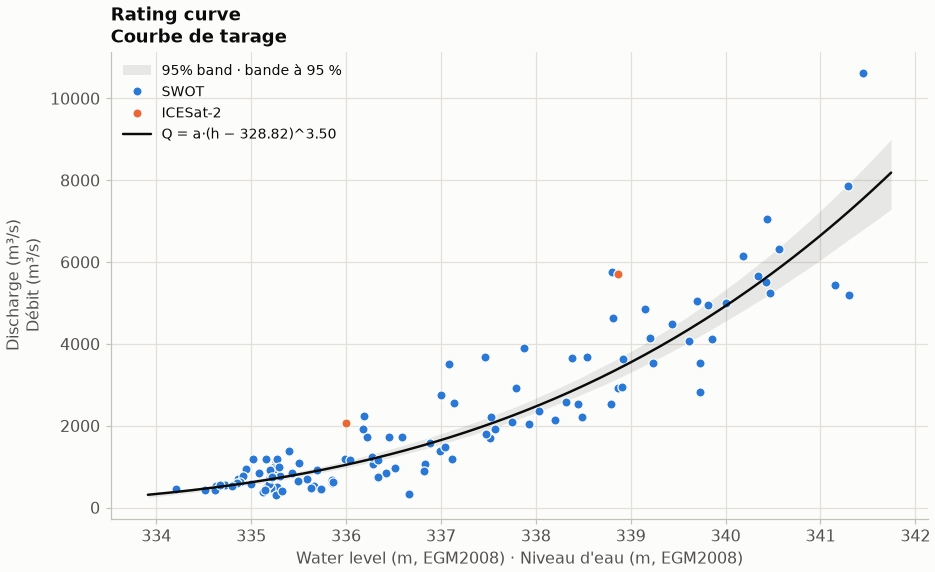

In [31]:
ubangi = vg.build_station("ubangi_bangui")   # ✏️
ubangi.rating()

### The whole world · Le monde entier

Large rivers of the world (darker = wider). Then zoom to a region by giving a point and a radius — here the Rewa in Fiji. Change the numbers to look at your own river.

> Les grands fleuves du monde (plus foncé = plus large). Puis zoomez sur une région avec un point et un rayon — ici la Rewa aux Fidji. Changez les nombres pour voir votre propre rivière.

In [32]:
vg.world_map()

In [33]:
vg.world_map(lat=-17.96, lon=178.43, radius_km=150)   # ✏️ your region · votre région

In [34]:
vg.reaches_near(lat=-17.96, lon=178.43)   # ✏️

,reach_id,river,width_m,km,lat,lon,build
0,55200000051,Rewa River,169,0.6,-18,178,"vg.build_station(""55200000051"")"
1,55200000211,,63,3.8,-18,178,"vg.build_station(""55200000211"")"
2,55200000061,Rewa River,123,6.9,-17.9,178,"vg.build_station(""55200000061"")"
3,55200000301,,42,7.6,-18,178,"vg.build_station(""55200000301"")"
4,55200000221,,51,7.8,-17.9,178,"vg.build_station(""55200000221"")"
5,55200000321,,42,8.2,-18,178,"vg.build_station(""55200000321"")"
6,55200000041,Rewa River,256,8.9,-18,179,"vg.build_station(""55200000041"")"
7,55200000291,,51,9.6,-18,178,"vg.build_station(""55200000291"")"
8,55200000231,,63,11.5,-18,178,"vg.build_station(""55200000231"")"
9,55200000271,,54,14.1,-18,178,"vg.build_station(""55200000271"")"


### Any river · N'importe quelle rivière

Paste a reach ID from a map or table into the line below. Reaches not shipped with the package need internet (20–60 s). Or use the box underneath.

> Collez un identifiant de tronçon d'une carte ou d'un tableau dans la ligne ci-dessous. Les tronçons non fournis demandent internet (20 à 60 s). Ou utilisez la boîte en dessous.

In [35]:
my = vg.build_station("PASTE-A-REACH-ID")   # ✏️ e.g. · ex. "13279300031"
my.levels()

Not available · Non disponible
This station could not be built: Unknown site · Site inconnu : 'PASTE-A-REACH-ID'. Known · Connus : ['congo_kinshasa', 'congo_kisangani', 'congo_mbandaka', 'kasai_kwamouth', 'lualaba_kindu', 'rewa_fiji', 'sangha_ouesso', 'ubangi_bangui'] · Cette station n'a pas pu être construite : Unknown site · Site inconnu : 'PASTE-A-REACH-ID'. Known · Connus : ['congo_kinshasa', 'congo_kisangani', 'congo_mbandaka', 'kasai_kwamouth', 'lualaba_kindu', 'rewa_fiji', 'sangha_ouesso', 'ubangi_bangui']

In [36]:
vg.explore_locations()

## Summary · Résumé

- Satellites give water levels above the **EGM2008 geoid**; your gauge reads from its own zero.
- **Cleaning** makes the station: a narrow water mask, slope correction, and the "water flows downhill" check.
- A rating curve is only as good as its **reference discharge** — and satellite levels can expose a biased model.
- Large, slow rivers suit altimetry; small, flashy, tidal rivers still need ground gauges.

For the full method and code, see the trainer notebook `Virtual_River_Gauges_DRC_Fiji.ipynb`.

> - Les satellites donnent des niveaux au-dessus du **géoïde EGM2008** ; votre échelle lit depuis son propre zéro.
> - Le **nettoyage** fait la station : masque d'eau étroit, correction de pente, et contrôle « l'eau descend ».
> - Une courbe de tarage ne vaut que son **débit de référence** — et les niveaux satellitaires peuvent révéler un modèle biaisé.
> - Les grands fleuves lents se prêtent à l'altimétrie ; les petites rivières rapides et à marée ont toujours besoin de stations au sol.
>
> Pour la méthode complète et le code, voir le notebook formateur `Virtual_River_Gauges_DRC_Fiji.ipynb`.

In [37]:
vg.credits()

Data: ICESat-2 ATL13 v007 (NASA/NSIDC, doi:10.5067/ATLAS/ATL13.007) via SlideRule Earth; SWOT RiverSP Version D (NASA/CNES, PO.DAAC) via Hydrocron; GEOGloWS v2 (ECMWF); SWORD v17b river database (Altenau et al. 2021, CC BY 4.0). Optional: GRDC, DAHITI (CC BY 4.0). · Données : ICESat-2 ATL13 v007 (NASA/NSIDC, doi:10.5067/ATLAS/ATL13.007) via SlideRule Earth ; SWOT RiverSP Version D (NASA/CNES, PO.DAAC) via Hydrocron ; GEOGloWS v2 (ECMWF) ; base de rivières SWORD v17b (Altenau et al. 2021, CC BY 4.0). Facultatif : GRDC, DAHITI (CC BY 4.0).